<a href="https://colab.research.google.com/github/DataScience-Fatec-Projects/ICD-004-Analise_de_Algoritmos/blob/main/Aulas/10/atividade07-dijkstra-bellman-ford.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Atividade 07 - Dijkstra com Min-Heap (heapq) e Bellman-Ford**
### Fatec Deputado Ary Fossen - Jundiaí
**Disciplina:** ICD-004 - Análise de Algoritmos

**Integrantes:** Wellington Junior Torres de Melo

---

## Enunciado

> **QUESTÃO 1:** A biblioteca `heapq` (que implementa um Min-Heap, ou Fila de Prioridade Mínima) é
> crucial para a implementação eficiente do Algoritmo de Dijkstra. A principal razão para usá-la é a
> otimização da complexidade temporal do algoritmo, especialmente na etapa mais repetitiva do processo.
> Compare a implementação com Min-Heap e uma sem o Min-Heap. Nessa comparação, mostre as diferenças
> entre as 2 implementações, especialmente com relação à sua complexidade. Explique o que é o Min-Heap
> (ou Heap Mínimo), em qual estrutura de dados ele se baseia e por que é usado no Algoritmo de Dijkstra.
>
> **QUESTÃO 2:** O Algoritmo de Dijkstra é aplicado em grafos ponderados com pesos apenas positivos em
> suas arestas. Para arestas com pesos negativos temos que implementar outro tipo de solução, como o
> Algoritmo de Bellman-Ford. Implemente esse algoritmo e descreva seu funcionamento e passo a passo com
> detalhes (como se fosse uma aula). Também mostre qual é a complexidade atrelada ao algoritmo.

## Roteiro

| Parte | Conteúdo |
|---|---|
| **1.1** | A implementação da aula (`dijkstra_heap.py`) e o grafo do metrô da Atividade 06, agora com tempo de viagem |
| **1.2** | O que é um Min-Heap, em que estrutura ele se baseia e por que o Dijkstra precisa dele |
| **1.3 e 1.4** | A versão sem heap, derivada da implementação da aula, e as duas lado a lado |
| **1.5** | Testes das duas versões no grafo da aula e no metrô |
| **1.6 e 1.7** | Complexidade: a conta no papel e a medição de tempo |
| **2.1 a 2.4** | Aula de Bellman-Ford: por que o Dijkstra falha, a ideia, o código e um exemplo passo a passo |
| **2.5 e 2.6** | Ciclo negativo e uma aplicação: arbitragem de câmbio |
| **2.7** | Complexidade do Bellman-Ford e conferência automática |


# Questão 1 - Dijkstra com e sem Min-Heap

## 1.1 A implementação da aula

O ponto de partida é a implementação disponibilizada na aula (`dijkstra_heap.py`, comentada pela IA
Gemini), reproduzida abaixo **sem alterações**. Ela recebe o grafo como **dicionário de dicionários**
(`grafo['A']['B'] = 7` é o peso da aresta A–B), a origem e o destino, e devolve a distância mínima e o
caminho. A fila de prioridade é a lista `fila_prioridade`, manipulada com `heapq.heappush` e
`heapq.heappop`.


In [1]:
# Comentado pela IA Gemini (2.5 Pro)

import heapq  # biblioteca para implementar a fila de prioridade (Min-Heap)
import math   # para usar 'infinito'

def dijkstra(grafo, origem, destino):
    """
    Implementa o algoritmo de Dijkstra para encontrar o caminho de menor custo.

    Args:
        grafo (dict): O grafo representado como um dicionário de dicionários.
                      Ex: {'A': {'B': 7, 'D': 9}, ...}
        origem (str): O nó de partida.
        destino (str): O nó de chegada.

    Returns:
        tuple: (distancia_minima, caminho_mais_curto)
    """

    # 1. Inicialização
    # Distâncias: Armazena a menor distância conhecida até cada nó
    distancias = {vertice: math.inf for vertice in grafo}
    distancias[origem] = 0

    # Predecessores: Armazena o nó anterior no caminho mais curto
    predecessores = {vertice: None for vertice in grafo}

    # Fila de Prioridade (Min-Heap): Armazena tuplas (distancia, vertice)
    # A prioridade é a distância, então o heappop() sempre extrai o de menor distância
    fila_prioridade = [(0, origem)]  # Começa com (distancia 0, nó origem)

    # 2. Iteração Principal
    while fila_prioridade:
        # Extrai o nó com a menor distância provisória
        distancia_atual, u = heapq.heappop(fila_prioridade)

        # Se a distância extraída for maior que a distância já conhecida,
        # significa que já encontramos um caminho mais curto para 'u', então ignoramos.
        if distancia_atual > distancias[u]:
            continue

        # Se chegamos ao destino, podemos parar e reconstruir o caminho
        if u == destino:
            break

        # 3. Relaxamento dos Vizinhos
        # Percorre todos os vizinhos (v) de 'u'
        for v, peso in grafo[u].items():
            nova_distancia = distancia_atual + peso

            # Se a nova distância é menor do que a distância registrada para 'v'
            if nova_distancia < distancias[v]:
                # Atualiza a distância e o predecessor
                distancias[v] = nova_distancia
                predecessores[v] = u

                # Adiciona ou atualiza 'v' na fila de prioridade
                heapq.heappush(fila_prioridade, (nova_distancia, v))

    # 4. Reconstrução do Caminho
    caminho = []
    atual = destino
    
    # Percorre os predecessores de trás para frente até chegar à origem
    while atual is not None:
        caminho.insert(0, atual)
        atual = predecessores[atual]

    # Verifica se o destino foi alcançado (se a distância é finita)
    if distancias[destino] == math.inf:
        return math.inf, "Caminho não encontrado"
    
    return distancias[destino], caminho


# Representação do Grafo (Lista de Adjacências usando dicionário)
# Note que o nosso grafo de exemplo era não-direcionado, então cada conexão
# deve ser listada duas vezes (ex: A->B e B->A)
grafo_exemplo = {
    'A': {'B': 7, 'D': 9},
    'B': {'A': 7, 'D': 1, 'E': 8},
    'C': {'E': 5, 'F': 4},
    'D': {'A': 9, 'B': 1, 'F': 10},
    'E': {'B': 8, 'C': 5, 'F': 6},
    'F': {'D': 10, 'C': 4, 'E': 6}
}

origem = 'A'
destino = 'C'

distancia_minima, caminho_final = dijkstra(grafo_exemplo, origem, destino)

print(f"Origem: {origem}")
print(f"Destino: {destino}")
print("-" * 30)
print(f"Distância Mínima: {distancia_minima}")
print(f"Caminho Mais Curto: {' -> '.join(caminho_final)}")


Origem: A
Destino: C
------------------------------
Distância Mínima: 20
Caminho Mais Curto: A -> B -> E -> C


### Um segundo grafo: o metrô da Atividade 06, agora com pesos

Na Atividade 06 a BFS achou o caminho com **menos trechos**, porque ali todas as arestas valiam o
mesmo. Agora cada aresta tem um **peso**, o tempo aproximado de viagem em minutos, e a pergunta passa a
ser *qual é o caminho mais rápido?*. O grafo segue o formato da implementação da aula:
`metro_min['Sé']['Paraíso'] == 7`. Consultar o peso de uma aresta é O(1) médio, pelo hash do `dict`
(Atividade 05).


In [2]:
from math import inf

# grafo do metro da atividade 06, agora PONDERADO
# peso = tempo aproximado de viagem em minutos (sem contar o tempo de baldeacao)
# dicionario de dicionarios: metro_min[a][b] = minutos para ir de a ate b
metro_min = {
    'Jundiaí':               {'Palmeiras-Barra Funda': 70},                                   # L7
    'Palmeiras-Barra Funda': {'Jundiaí': 70, 'República': 6},
    'República':             {'Palmeiras-Barra Funda': 6, 'Luz': 2, 'Sé': 3, 'Paulista-Consolação': 4},
    'Luz':                   {'República': 2, 'Brás': 4, 'Sé': 3},
    'Brás':                  {'Luz': 4, 'Sé': 4},
    'Paulista-Consolação':   {'República': 4, 'Paraíso': 5},
    'Paraíso':               {'Paulista-Consolação': 5, 'Sé': 7},
    'Sé':                    {'Luz': 3, 'Brás': 4, 'República': 3, 'Paraíso': 7},
    'Aeroporto-Guarulhos':   {'Engenheiro Goulart': 9},                                       # L13
    'Engenheiro Goulart':    {'Aeroporto-Guarulhos': 9},
}

total_arestas = sum(len(vizinhos) for vizinhos in metro_min.values()) // 2
simetrico = all(metro_min[b][a] == p for a in metro_min for b, p in metro_min[a].items())
print(f"{len(metro_min)} vértices, {total_arestas} arestas, mesmo tempo nos dois sentidos: {simetrico}")
print("vizinhos da Sé:", metro_min['Sé'])


10 vértices, 11 arestas, mesmo tempo nos dois sentidos: True
vizinhos da Sé: {'Luz': 3, 'Brás': 4, 'República': 3, 'Paraíso': 7}


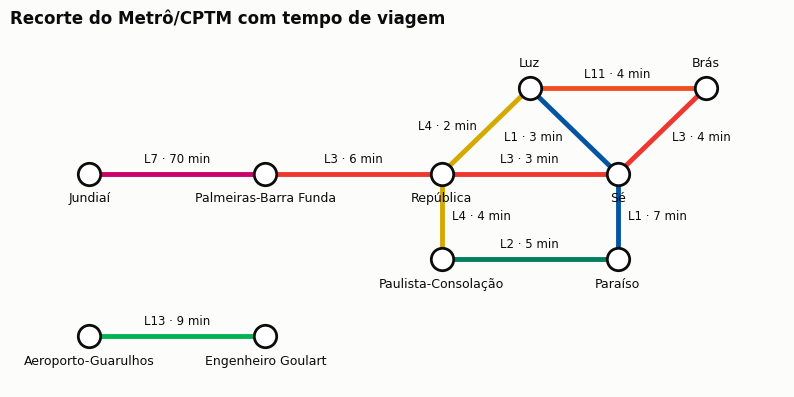

In [3]:
import matplotlib.pyplot as plt

TINTA, TINTA_2, FUNDO = '#0b0b0b', '#52514e', '#fcfcfb'    # texto principal, secundario e fundo
AZUL, LARANJA = '#2a78d6', '#eb6834'                        # duas primeiras cores da paleta categorica

# posicao de cada estacao no desenho (mesmo layout da atividade 06)
POS = {
    'Jundiaí': (0, 1), 'Palmeiras-Barra Funda': (2, 1), 'República': (4, 1), 'Sé': (6, 1),
    'Luz': (5, 2), 'Brás': (7, 2), 'Paulista-Consolação': (4, 0), 'Paraíso': (6, 0),
    'Aeroporto-Guarulhos': (0, -0.9), 'Engenheiro Goulart': (2, -0.9),
}
# a linha pertence a aresta: cor oficial de cada linha do Metro/CPTM
LINHA = {
    frozenset({'Jundiaí', 'Palmeiras-Barra Funda'}): ('L7', '#CA016B'),
    frozenset({'Palmeiras-Barra Funda', 'República'}): ('L3', '#EE372F'),
    frozenset({'República', 'Sé'}): ('L3', '#EE372F'),
    frozenset({'Brás', 'Sé'}): ('L3', '#EE372F'),
    frozenset({'Luz', 'Sé'}): ('L1', '#0455A1'),
    frozenset({'Sé', 'Paraíso'}): ('L1', '#0455A1'),
    frozenset({'República', 'Luz'}): ('L4', '#D4A900'),
    frozenset({'República', 'Paulista-Consolação'}): ('L4', '#D4A900'),
    frozenset({'Paulista-Consolação', 'Paraíso'}): ('L2', '#007E5E'),
    frozenset({'Luz', 'Brás'}): ('L11', '#F04E23'),
    frozenset({'Aeroporto-Guarulhos', 'Engenheiro Goulart'}): ('L13', '#00B352'),
}
# rotulo das diagonais: deslocamento (dx, dy) e alinhamento, para nao encostar nos nomes
ROTULO_DIAGONAL = {
    frozenset({'República', 'Luz'}): (-0.1, 0.05, 'right'),
    frozenset({'Luz', 'Sé'}): (-0.12, -0.08, 'right'),
    frozenset({'Brás', 'Sé'}): (0.12, -0.08, 'left'),
}


def desenhar_metro(grafo, caminho=None, titulo="Recorte do Metrô/CPTM com tempo de viagem"):
    """Desenha o grafo ponderado; se receber um caminho, destaca-o."""
    no_caminho = {frozenset(p) for p in zip(caminho, caminho[1:])} if caminho else set()
    fig, ax = plt.subplots(figsize=(10, 4.6), facecolor=FUNDO)
    ax.set_facecolor(FUNDO)
    vistas = set()
    for estacao, vizinhos in grafo.items():
        for vizinho, minutos in vizinhos.items():
            aresta = frozenset({estacao, vizinho})
            if aresta in vistas:                     # cada aresta aparece 2x no dict; desenha 1x
                continue
            vistas.add(aresta)
            nome, cor = LINHA[aresta]
            (x1, y1), (x2, y2) = POS[estacao], POS[vizinho]
            destaque = aresta in no_caminho
            ax.plot([x1, x2], [y1, y2], color=cor, lw=7 if destaque else 3.5,
                    alpha=1 if (destaque or not caminho) else 0.3, zorder=1, solid_capstyle='round')
            vertical = x1 == x2
            if aresta in ROTULO_DIAGONAL:
                dx, dy, ha = ROTULO_DIAGONAL[aresta]
                va = 'center'
            else:
                dx, dy = (0.12, 0) if vertical else (0, 0.09)
                ha, va = ('left', 'center') if vertical else ('center', 'bottom')
            ax.text((x1 + x2) / 2 + dx, (y1 + y2) / 2 + dy, f"{nome} · {minutos} min", color=TINTA,
                    fontsize=8.5, fontweight='bold' if destaque else 'normal', ha=ha, va=va)
    for estacao, (x, y) in POS.items():
        dentro = caminho and estacao in caminho
        ax.scatter(x, y, s=260, color=TINTA if dentro else 'white', edgecolor=TINTA, lw=2, zorder=2)
        em_cima = y == 2                             # Luz e Bras: nome acima, longe dos tracos
        ax.text(x, y + 0.22 if em_cima else y - 0.22, estacao, ha='center',
                va='bottom' if em_cima else 'top', fontsize=9, color=TINTA,
                fontweight='bold' if dentro else 'normal')
    ax.set_title(titulo, loc='left', fontweight='bold', color=TINTA)
    ax.set_xlim(-0.9, 7.9); ax.set_ylim(-1.5, 2.65); ax.axis('off')
    plt.show()


desenhar_metro(metro_min)


### O algoritmo, seguindo os comentários do código da aula

1. **Inicialização:** toda distância começa em ∞, menos a da origem, que é 0; nenhum vértice tem
   predecessor; o heap começa com `(0, origem)`.
2. **Iteração principal:** retirar do heap o vértice de **menor distância provisória** (`heappop`).
   Tuplas velhas (com distância maior que a já conhecida) são ignoradas. Se o vértice for o destino, o
   laço para, porque a distância dele já é **definitiva**.
3. **Relaxamento dos vizinhos:** para cada vizinho `v`, se `distancia_atual + peso < distancias[v]`,
   achamos um caminho melhor: atualiza `distancias[v]`, guarda `u` como predecessor de `v` e insere
   `(nova_distancia, v)` no heap.
4. **Reconstrução do caminho:** volta pelos predecessores, do destino até a origem.

A etapa 2 se repete **uma vez para cada vértice (V vezes)** e é a mais repetida e mais cara do
algoritmo. Toda a diferença entre as duas implementações está em **como** ela acha o menor:

- **sem heap:** olhar todos os vértices, um por um, atrás do menor, gastando O(V) a cada vez;
- **com heap (aula):** pegar o menor no topo do Min-Heap, gastando O(log V).


## 1.2 O que é um Min-Heap

**Fila de prioridade** é um tipo abstrato de dado: uma coleção da qual sempre se retira o item de
**maior prioridade** primeiro. No Dijkstra, prioridade = **menor distância**. Ela precisa de duas
operações rápidas: *inserir* um item e *retirar o mínimo*.

O **Min-Heap** (heap binário mínimo) é a forma mais usada de implementar essa fila. Ele é:

- **uma árvore binária completa:** todos os níveis estão cheios, menos talvez o último, que é preenchido
  da esquerda para a direita. Com n itens a altura é ⌊log₂ n⌋; com 1 milhão de itens, só 19 níveis;
- **com a propriedade de heap:** todo pai é **menor ou igual** aos seus filhos. Por isso o menor item
  está sempre na **raiz**.

**Em que estrutura ele se baseia:** a ideia é a de uma **árvore binária**, mas ela é guardada em um
**vetor (lista do Python)**, sem ponteiros. Como a árvore é completa, não sobra buraco na lista e as
posições de pai e filhos saem de contas simples:

| Para o índice `i` | Fórmula |
|---|---|
| filho da esquerda | `2*i + 1` |
| filho da direita | `2*i + 2` |
| pai | `(i - 1) // 2` |

Um heap **não é uma lista ordenada**. Ele só garante *pai ≤ filhos*; irmãos e primos podem estar em
qualquer ordem. É justamente por manter só essa garantia parcial que inserir e retirar ficam baratos.

| Operação | Em `heapq` | Como funciona | Custo |
|---|---|---|---|
| ver o mínimo | `heap[0]` | é a raiz | O(1) |
| inserir | `heappush(heap, x)` | coloca `x` no fim da lista e o faz **subir** (*sift-up*), trocando com o pai enquanto for menor | O(log n) |
| retirar o mínimo | `heappop(heap)` | tira a raiz, põe o último item no lugar e o faz **descer** (*sift-down*), trocando com o menor filho | O(log n) |
| montar de uma lista | `heapify(lista)` | aplica o *sift-down* de baixo para cima | O(n) |

No Python, o `heapq` não é uma classe: são funções que tratam uma `list` comum como heap (no código
da aula, a `fila_prioridade`), e o heap é sempre **mínimo** (para um heap máximo, guarda-se o valor
negativo). Abaixo, oito valores inseridos um por um:


In [4]:
import heapq

heap = []                                   # um heap do heapq e uma lista comum do Python
for valor in [8, 3, 10, 1, 6, 14, 4, 7]:
    heapq.heappush(heap, valor)             # poe no fim e "sobe" enquanto for menor que o pai
    print(f"push {valor:>2}  ->  {str(heap):<28} topo heap[0] = {heap[0]}")

print("\níndice  valor  pai  filhos")
for i, valor in enumerate(heap):
    pai = (i - 1) // 2 if i > 0 else '-'
    filhos = [heap[f] for f in (2 * i + 1, 2 * i + 2) if f < len(heap)]
    print(f"{i:>6}  {valor:>5}  {str(pai):>3}  {filhos}")


push  8  ->  [8]                          topo heap[0] = 8
push  3  ->  [3, 8]                       topo heap[0] = 3
push 10  ->  [3, 8, 10]                   topo heap[0] = 3
push  1  ->  [1, 3, 10, 8]                topo heap[0] = 1
push  6  ->  [1, 3, 10, 8, 6]             topo heap[0] = 1
push 14  ->  [1, 3, 10, 8, 6, 14]         topo heap[0] = 1
push  4  ->  [1, 3, 4, 8, 6, 14, 10]      topo heap[0] = 1
push  7  ->  [1, 3, 4, 7, 6, 14, 10, 8]   topo heap[0] = 1

índice  valor  pai  filhos
     0      1    -  [3, 4]
     1      3    0  [7, 6]
     2      4    0  [14, 10]
     3      7    1  [8]
     4      6    1  []
     5     14    2  []
     6     10    2  []
     7      8    3  []


Repare no `push 1`: ele entrou no fim da lista (índice 3), era menor que o pai (8, índice 1) e
trocou; depois era menor que o novo pai (3, índice 0) e trocou de novo, chegando à raiz. Foram **2
trocas** para 4 itens, ou seja, no máximo a altura da árvore. E a lista final `[1, 3, 4, 7, 6, 14, 10, 8]`
**não está ordenada** (o 7 vem antes do 6), mas todo pai é menor que os filhos:


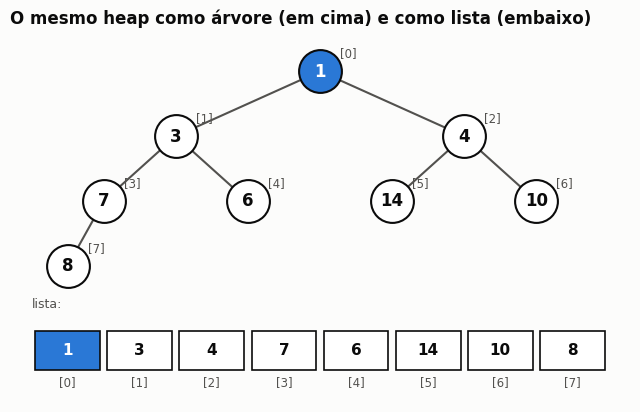

In [5]:
import math


def desenhar_heap(heap, titulo="O mesmo heap como árvore (em cima) e como lista (embaixo)"):
    """Desenha a arvore binaria completa e, embaixo, a lista que a guarda."""
    n = len(heap)
    niveis = math.floor(math.log2(n)) + 1
    pos = {}
    for i in range(n):
        nivel = math.floor(math.log2(i + 1))     # o indice i fica no nivel floor(log2(i+1))
        k = i - (2 ** nivel - 1)                 # posicao dentro do nivel
        pos[i] = ((k + 0.5) / 2 ** nivel * n, niveis - nivel + 0.6)
    fig, ax = plt.subplots(figsize=(8, 4.8), facecolor=FUNDO)
    ax.set_facecolor(FUNDO)
    for i in range(1, n):                        # liga cada no ao pai (i - 1) // 2
        p = (i - 1) // 2
        ax.plot([pos[p][0], pos[i][0]], [pos[p][1], pos[i][1]], color=TINTA_2, lw=1.5, zorder=1)
    for i, (x, y) in pos.items():
        topo = i == 0
        ax.scatter(x, y, s=950, color=AZUL if topo else 'white', edgecolor=TINTA, lw=1.5, zorder=2)
        ax.text(x, y, str(heap[i]), ha='center', va='center', fontsize=12, fontweight='bold',
                color='white' if topo else TINTA, zorder=3)
        ax.text(x + 0.28, y + 0.22, f"[{i}]", fontsize=8.5, color=TINTA_2)
    for i, valor in enumerate(heap):             # a lista: cada caixa e uma posicao
        ax.add_patch(plt.Rectangle((i + 0.05, 0), 0.9, 0.6, facecolor=AZUL if i == 0 else 'white',
                                   edgecolor=TINTA, lw=1.2))
        ax.text(i + 0.5, 0.3, str(valor), ha='center', va='center', fontsize=11, fontweight='bold',
                color='white' if i == 0 else TINTA)
        ax.text(i + 0.5, -0.2, f"[{i}]", ha='center', va='center', fontsize=8.5, color=TINTA_2)
    ax.text(0, 0.95, "lista:", fontsize=9, color=TINTA_2)
    ax.set_title(titulo, loc='left', fontweight='bold', color=TINTA)
    ax.set_xlim(-0.3, n + 0.3); ax.set_ylim(-0.5, niveis + 1.2); ax.axis('off')
    plt.show()


desenhar_heap(heap)


In [6]:
# heappop sempre devolve o menor: tirar tudo da a lista em ordem crescente
copia = heap[:]
print("ordem dos heappop:", [heapq.heappop(copia) for _ in range(len(copia))])

# heapify transforma uma lista qualquer em heap, no lugar, em O(n)
lista = [8, 3, 10, 1, 6, 14, 4, 7]
heapq.heapify(lista)
print("heapify:          ", lista)

# no Dijkstra o heap guarda tuplas (distancia, vertice): a tupla e comparada pelo
# primeiro elemento, e so em caso de empate pelo segundo
fila = []
for item in [(79, 'Sé'), (78, 'Luz'), (80, 'Paulista-Consolação'), (78, 'Brás')]:
    heapq.heappush(fila, item)
print("menor (dist, estação):", heapq.heappop(fila), "| próximo:", fila[0])


ordem dos heappop: [1, 3, 4, 6, 7, 8, 10, 14]
heapify:           [1, 3, 4, 7, 6, 14, 10, 8]
menor (dist, estação): (78, 'Brás') | próximo: (78, 'Luz')


### Por que o Min-Heap é usado no Dijkstra

O Dijkstra repete o tempo todo duas coisas: **retirar o vértice de menor distância** (V vezes) e
**atualizar a distância de um vizinho** (até E vezes). Toda estrutura de fila de prioridade é uma troca
entre essas duas operações:

| Como guardar as distâncias provisórias | atualizar / inserir | retirar o mínimo | Dijkstra fica |
|---|---|---|---|
| dicionário/lista **sem ordem** (versão "sem heap") | O(1) | O(V), varre tudo | **O(V²)** |
| lista **ordenada** | O(V), achar a posição e deslocar | O(1) | O(V·E) |
| **Min-Heap binário** (`heapq`) | O(log V) | O(log V) | **O((V + E) log V)** |
| heap de Fibonacci (teórico) | O(1) amortizado | O(log V) amortizado | O(E + V log V) |

O heap é a estrutura que deixa **as duas** operações baratas ao mesmo tempo, e ainda vem pronto na
biblioteca padrão. O heap de Fibonacci tem a melhor complexidade no papel, mas é complicado e, na
prática, costuma perder para o heap binário.

**Detalhe de implementação: a "remoção preguiçosa" (*lazy deletion*).** O `heapq` não tem a operação
"diminuir a chave de um item que já está no heap". Por isso, quando a distância de um vértice melhora,
o código da aula simplesmente **insere outra tupla** `(nova_distancia, v)` ("Adiciona ou atualiza 'v'
na fila de prioridade"). A tupla velha continua lá dentro e, quando sair do heap, é descartada pelo
teste `if distancia_atual > distancias[u]: continue`. Com isso o heap pode chegar a ter até E itens,
mas como E ≤ V², log E ≤ 2·log V, e o custo de cada operação continua O(log V).


## 1.3 Implementação sem Min-Heap

Primeiro, três funções auxiliares usadas nos testes e na questão 2: `fmt` mostra ∞, `custo` soma os
pesos de um trajeto e `milhar` separa os milhares nos números grandes.


In [7]:
def fmt(x):
    """Mostra infinito como o simbolo, e numeros sem casas decimais inuteis."""
    return '∞' if x == inf else f'{x:g}'


def custo(grafo, trajeto):
    """Soma dos pesos das arestas de um caminho."""
    return sum(grafo[a][b] for a, b in zip(trajeto, trajeto[1:]))


def milhar(n):
    """Inteiro com espaco separando os milhares: 3996001 -> '3 996 001'."""
    return f"{n:,}".replace(",", " ")


A versão sem heap é **a mesma função da aula**, com a mesma assinatura e o mesmo retorno, trocando
só a fila de prioridade. Os comentários originais foram mantidos, e os trechos que mudaram estão
marcados com `>>> SEM HEAP`. Sem o heap:

- a escolha do próximo vértice vira um laço que **varre todos os vértices** atrás do não visitado de
  menor distância. Esse laço roda dentro de outro de até V voltas, então custa **V × V = V²**;
- é preciso um conjunto `visitados`, porque não existe mais o heap para dizer quem é o próximo;
- não há `heappush` nem tuplas velhas: a próxima varredura já enxerga a distância atualizada.


In [8]:
def dijkstra_sem_heap(grafo, origem, destino):
    """
    A mesma implementação da aula (dijkstra_heap.py), trocando o Min-Heap por uma varredura.
    Mesma assinatura e mesmo retorno: (distancia_minima, caminho_mais_curto).
    Os trechos que mudaram estão marcados com  >>> SEM HEAP
    """

    # 1. Inicialização
    distancias = {vertice: math.inf for vertice in grafo}
    distancias[origem] = 0
    predecessores = {vertice: None for vertice in grafo}

    # >>> SEM HEAP: no lugar da fila de prioridade, um conjunto com os nós já processados
    visitados = set()

    # 2. Iteração Principal
    # >>> SEM HEAP: no máximo uma volta por vértice
    while len(visitados) < len(grafo):
        # >>> SEM HEAP: extrai o nó com a menor distância provisória VARRENDO todos -> O(V)
        u = None
        for vertice in grafo:
            if vertice not in visitados and (u is None or distancias[vertice] < distancias[u]):
                u = vertice
        if distancias[u] == math.inf:
            break                                # os que sobraram não são alcançáveis
        visitados.add(u)
        distancia_atual = distancias[u]

        # Se chegamos ao destino, podemos parar e reconstruir o caminho
        if u == destino:
            break

        # 3. Relaxamento dos Vizinhos
        for v, peso in grafo[u].items():
            nova_distancia = distancia_atual + peso
            if nova_distancia < distancias[v]:
                distancias[v] = nova_distancia
                predecessores[v] = u
                # >>> SEM HEAP: sem heappush; a próxima varredura já enxerga a nova distância

    # 4. Reconstrução do Caminho (igual)
    caminho = []
    atual = destino
    while atual is not None:
        caminho.insert(0, atual)
        atual = predecessores[atual]

    if distancias[destino] == math.inf:
        return math.inf, "Caminho não encontrado"

    return distancias[destino], caminho


## 1.4 As duas versões lado a lado

As etapas 1 (inicialização) e 4 (reconstrução do caminho) e o `break` no destino são iguais. Só mudam
**dois trechos**:

**Escolher o próximo vértice (etapa 2):**

```python
# COM heap (aula): o menor esta no topo -> O(log V)
distancia_atual, u = heapq.heappop(fila_prioridade)
if distancia_atual > distancias[u]:
    continue
```

```python
# SEM heap: varre os V vertices -> O(V)
u = None
for vertice in grafo:
    if vertice not in visitados and (u is None or distancias[vertice] < distancias[u]):
        u = vertice
visitados.add(u)
```

**Atualizar a distância de um vizinho (etapa 3):**

```python
distancias[v] = nova_distancia
predecessores[v] = u
heapq.heappush(fila_prioridade, (nova_distancia, v))   # COM heap: tambem avisa o heap, O(log V)
```

```python
distancias[v] = nova_distancia
predecessores[v] = u                                   # SEM heap: so isso, O(1)
```

| | Sem Min-Heap | Com Min-Heap (implementação da aula) |
|---|---|---|
| Estrutura | `distancias` + conjunto `visitados` | `distancias` + `fila_prioridade` (heap de tuplas `(distância, vértice)`) |
| Laço principal | `while len(visitados) < len(grafo)` | `while fila_prioridade` |
| Escolher o mínimo | varredura linear, **O(V)** | `heappop`, **O(log V)** |
| Atualizar uma distância | O(1) | O(log V) (`heappush`) |
| Entradas velhas | não existem | descartadas com `if distancia_atual > distancias[u]` |
| Memória extra | O(V) | O(V + E) (o heap pode guardar cópias velhas) |
| **Tempo total** | **O(V²)** | **O((V + E) log V)** |
| Melhor para | grafos **densos** (E perto de V²) | grafos **esparsos** (E perto de V), o caso comum |


## 1.5 Testando as duas versões

As duas versões rodam no grafo de exemplo da aula (de A até cada vértice) e no metrô (de Jundiaí até
cada estação), e o `assert` confere que elas dão exatamente as mesmas distâncias. Depois, o caminho
Jundiaí → Paraíso é comparado com a resposta da BFS da Atividade 06.


In [9]:
# 1) grafo de exemplo da aula: de A ate cada vertice, nas duas versoes
print(f"{'A até':<6} {'sem heap':>8} {'com heap':>8}   caminho (com heap)")
for destino in grafo_exemplo:
    d_sem, _ = dijkstra_sem_heap(grafo_exemplo, 'A', destino)
    d_com, rota = dijkstra(grafo_exemplo, 'A', destino)
    assert d_sem == d_com                        # as duas versoes tem que concordar
    print(f"{destino:<6} {fmt(d_sem):>8} {fmt(d_com):>8}   {' → '.join(rota)}")

# 2) metro: de Jundiai ate cada estacao
resultados = []
for estacao in metro_min:
    d_sem, _ = dijkstra_sem_heap(metro_min, 'Jundiaí', estacao)
    d_com, rota = dijkstra(metro_min, 'Jundiaí', estacao)
    assert d_sem == d_com
    resultados.append((d_com, estacao, d_sem, rota))

print(f"\n{'Jundiaí até':<22} {'sem heap':>8} {'com heap':>8}   caminho (com heap)")
for d_com, estacao, d_sem, rota in sorted(resultados, key=lambda r: r[0]):
    texto = ' → '.join(rota) if d_com < inf else rota        # rota = "Caminho não encontrado"
    print(f"{estacao:<22} {fmt(d_sem):>8} {fmt(d_com):>8}   {texto}")

rota_bfs = ['Jundiaí', 'Palmeiras-Barra Funda', 'República', 'Sé', 'Paraíso']   # resposta da BFS (atividade 06)
_, rota_dij = dijkstra(metro_min, 'Jundiaí', 'Paraíso')
print("\nJundiaí → Paraíso")
print(f"  BFS      (menos trechos): {' → '.join(rota_bfs)}  = {len(rota_bfs) - 1} trechos, {custo(metro_min, rota_bfs)} min")
print(f"  Dijkstra (menos tempo):   {' → '.join(rota_dij)}  = {len(rota_dij) - 1} trechos, {custo(metro_min, rota_dij)} min")


A até  sem heap com heap   caminho (com heap)
A             0        0   A
B             7        7   A → B
C            20       20   A → B → E → C
D             8        8   A → B → D
E            15       15   A → B → E
F            18       18   A → B → D → F

Jundiaí até            sem heap com heap   caminho (com heap)
Jundiaí                       0        0   Jundiaí
Palmeiras-Barra Funda        70       70   Jundiaí → Palmeiras-Barra Funda
República                    76       76   Jundiaí → Palmeiras-Barra Funda → República
Luz                          78       78   Jundiaí → Palmeiras-Barra Funda → República → Luz
Sé                           79       79   Jundiaí → Palmeiras-Barra Funda → República → Sé
Paulista-Consolação          80       80   Jundiaí → Palmeiras-Barra Funda → República → Paulista-Consolação
Brás                         82       82   Jundiaí → Palmeiras-Barra Funda → República → Luz → Brás
Paraíso                      85       85   Jundiaí → Palmeiras-Bar

As duas versões concordam em todos os destinos dos dois grafos. No grafo da aula, A → C custa 20
pelo caminho A → B → E → C, o mesmo resultado impresso pelo `dijkstra_heap.py`. No metrô, o
Aeroporto-Guarulhos continua inalcançável (as duas versões devolvem "Caminho não encontrado"), como na
BFS.

O ponto interessante é **Jundiaí → Paraíso**: a BFS escolheu o caminho pela Sé porque ele tem o menor
número de trechos (4), mas existe outro caminho com os mesmos 4 trechos, pela L4 e pela L2, que leva
**85 min em vez de 86**. A BFS não enxerga esse minuto; o Dijkstra enxerga, porque soma os pesos.

### O heap trabalhando

A função abaixo é o mesmo laço da implementação da aula, só com `print`. Cada linha mostra a tupla que
**saiu** do topo do heap e as tuplas que **entraram** ao relaxar os vizinhos:


In [10]:
def dijkstra_passo_a_passo(grafo, origem, destino):
    """O mesmo laco da implementacao da aula, imprimindo o que sai e o que entra no heap."""
    distancias = {vertice: inf for vertice in grafo}
    distancias[origem] = 0
    fila_prioridade = [(0, origem)]
    while fila_prioridade:
        distancia_atual, u = heapq.heappop(fila_prioridade)
        saiu = f"({distancia_atual}, {u})"
        if distancia_atual > distancias[u]:
            print(f"sai {saiu:<29} cópia velha ({distancia_atual} > {distancias[u]}): ignora")
            continue
        if u == destino:
            print(f"sai {saiu:<29} é o destino: break")
            break
        entraram = []
        for v, peso in grafo[u].items():
            nova_distancia = distancia_atual + peso
            if nova_distancia < distancias[v]:
                distancias[v] = nova_distancia
                heapq.heappush(fila_prioridade, (nova_distancia, v))
                entraram.append(f"({nova_distancia}, {v})")
        print(f"sai {saiu:<29} entra: {', '.join(entraram) or 'nada':<52} heap: {len(fila_prioridade)}")
    print("sobrou no heap:", fila_prioridade)


dijkstra_passo_a_passo(metro_min, 'Jundiaí', 'Paraíso')


sai (0, Jundiaí)                  entra: (70, Palmeiras-Barra Funda)                          heap: 1
sai (70, Palmeiras-Barra Funda)   entra: (76, República)                                      heap: 1
sai (76, República)               entra: (78, Luz), (79, Sé), (80, Paulista-Consolação)       heap: 3
sai (78, Luz)                     entra: (82, Brás)                                           heap: 3
sai (79, Sé)                      entra: (86, Paraíso)                                        heap: 3
sai (80, Paulista-Consolação)     entra: (85, Paraíso)                                        heap: 3
sai (82, Brás)                    entra: nada                                                 heap: 2
sai (85, Paraíso)                 é o destino: break
sobrou no heap: [(86, 'Paraíso')]


Pontos para observar:

- As tuplas saem em **ordem crescente de distância** (0, 70, 76, 78, 79, 80, 82, 85), mesmo tendo
  entrado fora de ordem. É o Min-Heap fazendo a etapa 2 sem varrer nada.
- O Paraíso entrou **duas vezes**: com 86 (vindo da Sé) e depois com 85 (vindo da
  Paulista-Consolação). A tupla `(85, 'Paraíso')` saiu primeiro e, como o Paraíso é o destino, o
  `break` encerrou a busca. A tupla `(86, 'Paraíso')` ficou sobrando no heap: se a busca continuasse,
  ela seria descartada pelo teste `distancia_atual > distancias[u]` (86 > 85). É a remoção preguiçosa
  da seção 1.2.
- Aeroporto-Guarulhos e Engenheiro Goulart nunca entram no heap, porque nenhuma aresta leva até eles.
  A versão sem heap, ao contrário, olha para eles em toda varredura.
- O `break` no destino economiza trabalho, mas não muda a complexidade: no pior caso o destino é o
  último a sair do heap (ou nem é alcançável), e o algoritmo processa o grafo inteiro.


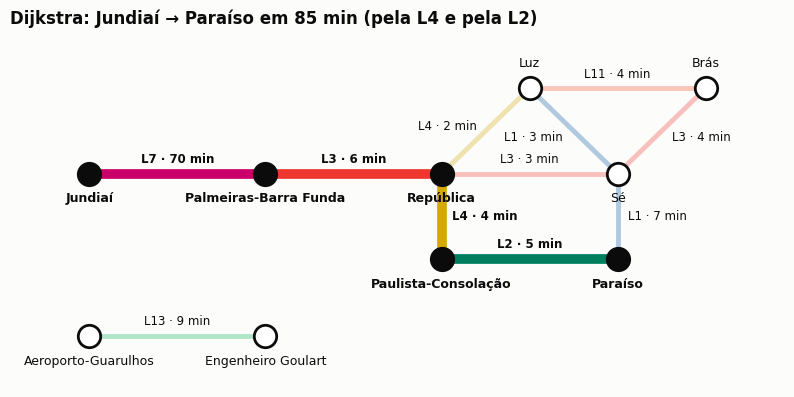

In [11]:
desenhar_metro(metro_min, rota_dij, titulo="Dijkstra: Jundiaí → Paraíso em 85 min (pela L4 e pela L2)")


## 1.6 Complexidade: a conta no papel

V = número de vértices, E = número de arestas.

**Sem Min-Heap**

| Etapa | Quantas vezes | Custo de cada | Total |
|---|---|---|---|
| inicializar `distancias` e `predecessores` | 1 | O(V) | O(V) |
| escolher o menor não visitado (varredura) | V | O(V) | **O(V²)** |
| relaxar uma aresta | E no total (cada aresta uma vez, quando a sua origem é visitada) | O(1) | O(E) |
| **total** | | | **O(V² + E) = O(V²)**, pois E ≤ V² |

**Com Min-Heap**

| Etapa | Quantas vezes | Custo de cada | Total |
|---|---|---|---|
| inicializar `distancias` e `predecessores` | 1 | O(V) | O(V) |
| `heappop` | até E + 1 (uma por tupla inserida, contando as velhas) | O(log E) = O(log V) | O(E log V) |
| relaxar uma aresta + `heappush` | até E | O(log V) | O(E log V) |
| **total** | | | **O((V + E) log V)** |

O `break` no destino, presente nas duas versões, não muda essas contas, porque no pior caso o destino
é o último vértice a ser processado.

**Quem ganha depende da densidade do grafo:**

- **Esparso** (E proporcional a V, como malhas viárias, redes de metrô, redes sociais): o heap faz
  O(V log V) contra O(V²) da varredura. A diferença cresce sem parar com o tamanho.
- **Denso** (E perto de V², todo mundo ligado a todo mundo): o heap faz O(V² log V) e a varredura faz
  O(V²). No pior caso teórico, a versão **sem** heap é melhor, porque ela relaxaria as V² arestas de
  qualquer jeito e não paga o `log V` de cada `heappush`.

A conta abaixo mostra a ordem de grandeza do número de operações:


In [12]:
from math import log2


def mostrar_contas(rotulo, arestas_de_v, tamanhos):
    print(rotulo)
    print(f"{'V':>11} {'E':>9} {'sem heap: V²':>14} {'com heap: (V+E)·log V':>23} {'quem faz menos':>16}")
    for V in tamanhos:
        E = arestas_de_v(V)
        lista, heap_ = V ** 2, (V + E) * log2(V)
        vencedor = f"heap, {milhar(round(lista / heap_))}x" if heap_ < lista else f"lista, {heap_ / lista:.1f}x"
        print(f"{milhar(V):>11} {E:>9.0e} {lista:>14.1e} {heap_:>23.1e} {vencedor:>16}")
    print()


mostrar_contas("ESPARSO (E = 5V, como uma malha viária)", lambda V: 5 * V, [10**3, 10**4, 10**5, 10**6])
mostrar_contas("DENSO (E = V², todos ligados a todos)", lambda V: V * V, [10**2, 10**3, 10**4])


ESPARSO (E = 5V, como uma malha viária)
          V         E   sem heap: V²   com heap: (V+E)·log V   quem faz menos
      1 000     5e+03        1.0e+06                 6.0e+04        heap, 17x
     10 000     5e+04        1.0e+08                 8.0e+05       heap, 125x
    100 000     5e+05        1.0e+10                 1.0e+07     heap, 1 003x
  1 000 000     5e+06        1.0e+12                 1.2e+08     heap, 8 362x

DENSO (E = V², todos ligados a todos)
          V         E   sem heap: V²   com heap: (V+E)·log V   quem faz menos
        100     1e+04        1.0e+04                 6.7e+04      lista, 6.7x
      1 000     1e+06        1.0e+06                 1.0e+07     lista, 10.0x
     10 000     1e+08        1.0e+08                 1.3e+09     lista, 13.3x



## 1.7 Complexidade na prática: medindo o tempo

As duas versões rodam em grafos aleatórios de tamanho crescente (sempre com a mesma semente, para o
resultado ser reproduzível). Para medir o algoritmo **inteiro**, o destino é um vértice extra sem
nenhuma aresta: ele nunca é alcançado, então o `break` não acontece e as duas versões processam o
grafo todo, que é o pior caso. Cada tempo é o melhor de 3 execuções, e antes disso o `assert` confere
que as duas versões dão a mesma distância para 3 destinos sorteados.


In [13]:
import random
import time


def grafo_aleatorio(n, saidas_por_vertice, semente=42):
    """Grafo direcionado com pesos de 1 a 100. O anel i -> i+1 garante que todos sao alcancaveis."""
    rng = random.Random(semente)
    grafo = {v: {} for v in range(n)}
    for u in range(n):
        grafo[u][(u + 1) % n] = rng.randint(1, 100)
        for v in rng.sample(range(n), min(saidas_por_vertice, n - 1)):
            if v != u:
                grafo[u][v] = rng.randint(1, 100)
    return grafo


def cronometrar(funcao, *argumentos, repeticoes=3):
    """Melhor tempo (em ms) entre algumas execucoes, para reduzir o ruido do sistema."""
    melhor = inf
    for _ in range(repeticoes):
        inicio = time.perf_counter()
        funcao(*argumentos)
        melhor = min(melhor, time.perf_counter() - inicio)
    return melhor * 1000


def comparar(tamanhos, saidas):
    """Mede as duas versoes em grafos de tamanho crescente e confere se dao a mesma resposta."""
    print(f"{'V':>6} {'E':>9} {'sem heap (ms)':>14} {'com heap (ms)':>14} {'razão':>8}")
    linhas = []
    for n in tamanhos:
        g = grafo_aleatorio(n, saidas(n))
        e = sum(len(viz) for viz in g.values())
        for destino in random.Random(n).sample(range(n), 3):      # confere 3 destinos sorteados
            assert dijkstra_sem_heap(g, 0, destino)[0] == dijkstra(g, 0, destino)[0]
        g[n] = {}      # destino isolado: nunca e alcancado, entao as duas versoes processam o grafo todo
        t_sem, t_com = cronometrar(dijkstra_sem_heap, g, 0, n), cronometrar(dijkstra, g, 0, n)
        linhas.append((n, e, t_sem, t_com))
        print(f"{milhar(n):>6} {milhar(e):>9} {t_sem:>14.1f} {t_com:>14.1f} {t_sem / t_com:>7.1f}x")
    return linhas


In [14]:
print("ESPARSO (cerca de 6 arestas saindo de cada vértice)")
esparso = comparar([250, 500, 1000, 2000, 4000], lambda n: 5)
print("\nDENSO (cada vértice ligado a todos os outros: E = V(V-1))")
denso = comparar([100, 200, 400, 800], lambda n: n - 1)


ESPARSO (cerca de 6 arestas saindo de cada vértice)
     V         E  sem heap (ms)  com heap (ms)    razão
   250     1 488            2.2            0.2    11.5x


   500     2 992            9.7            0.5    18.2x


 1 000     5 992           40.6            1.1    36.1x


 2 000    11 994          144.4            2.1    68.2x


 4 000    23 990          592.9            4.5   130.8x

DENSO (cada vértice ligado a todos os outros: E = V(V-1))
     V         E  sem heap (ms)  com heap (ms)    razão
   100     9 803            0.6            0.4     1.6x
   200    39 602            2.6            1.6     1.6x
   400   159 202           11.6            8.1     1.4x


   800   638 401           47.3           29.7     1.6x


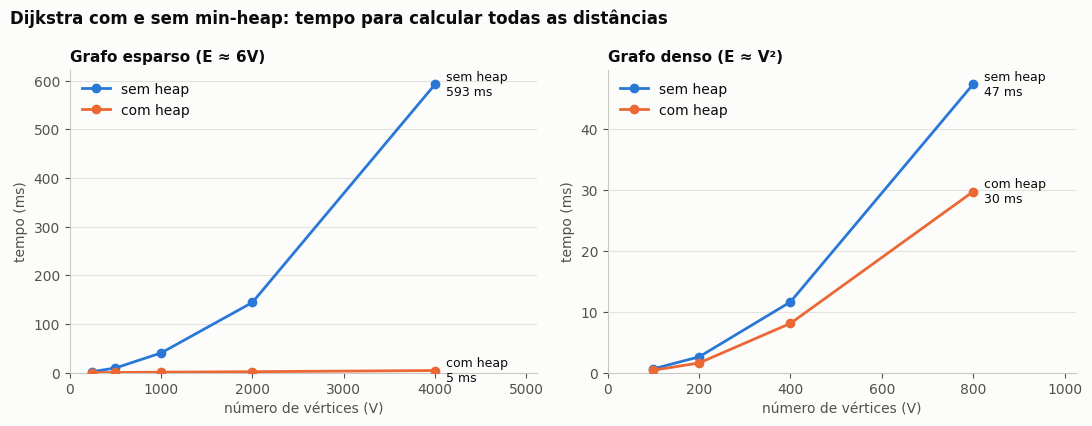

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.3), facecolor=FUNDO)
paineis = [(eixos[0], esparso, 'Grafo esparso (E ≈ 6V)'), (eixos[1], denso, 'Grafo denso (E ≈ V²)')]
for ax, dados, titulo in paineis:
    ax.set_facecolor(FUNDO)
    v = [linha[0] for linha in dados]
    for col, nome, cor in [(2, 'sem heap', AZUL), (3, 'com heap', LARANJA)]:
        t = [linha[col] for linha in dados]
        ax.plot(v, t, color=cor, lw=2, marker='o', ms=6, label=nome, zorder=3)
        ax.annotate(f"{nome}\n{t[-1]:.0f} ms", (v[-1], t[-1]), xytext=(8, 0),
                    textcoords='offset points', va='center', fontsize=9, color=TINTA)
    ax.set_title(titulo, loc='left', fontweight='bold', color=TINTA, fontsize=11)
    ax.set_xlabel('número de vértices (V)', color=TINTA_2)
    ax.set_ylabel('tempo (ms)', color=TINTA_2)
    ax.set_ylim(bottom=0)
    ax.set_xlim(0, v[-1] * 1.28)
    ax.grid(axis='y', color='#e4e3df', lw=0.8)
    ax.tick_params(colors=TINTA_2)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    for lado in ('left', 'bottom'):
        ax.spines[lado].set_color('#c9c8c2')
    ax.legend(frameon=False, loc='upper left', labelcolor=TINTA)
fig.suptitle('Dijkstra com e sem min-heap: tempo para calcular todas as distâncias',
             x=0.01, ha='left', fontweight='bold', color=TINTA)
fig.tight_layout()
plt.show()


### O que a medição mostra

**Grafo esparso.** Cada vez que V dobra, o tempo **sem heap** fica perto de **4 vezes maior**, que é o
comportamento de O(V²). O tempo **com heap** fica só em torno do dobro, quase linear, como se
espera de O((V + E) log V). Por isso a vantagem do heap **cresce com o tamanho do grafo**: cerca de
10× com 250 vértices e perto de 100× (ou mais) com 4 000. Os milissegundos mudam a cada execução, e
mais ainda no Colab, mas a tendência não.

**Grafo denso.** A razão fica **estável, entre 1× e 2×**, sem crescer: as duas curvas sobem no mesmo ritmo. Aqui
as duas versões fazem Θ(V²) operações: ambas precisam olhar as V(V − 1) arestas, e a varredura da
versão sem heap também é V². Pela seção 1.6, no pior caso a versão sem heap deveria até ganhar, mas
esse pior caso supõe que quase toda aresta melhora uma distância e vira um `heappush`. Com pesos
aleatórios isso quase não acontece:


In [16]:
# quantas arestas viram heappush de verdade? troca o heappush por uma versao que conta
contador = 0
heappush_original = heapq.heappush


def heappush_contando(heap, item):
    global contador
    contador += 1
    heappush_original(heap, item)


heapq.heappush = heappush_contando
try:
    for rotulo, n, saidas in [('esparso, V = 4000', 4000, 5), ('denso,   V =  800', 800, 799)]:
        g = grafo_aleatorio(n, saidas)
        e = sum(len(viz) for viz in g.values())
        g[n] = {}                                  # o mesmo destino isolado da medicao
        contador = 0
        dijkstra(g, 0, n)
        print(f"{rotulo}: {milhar(contador):>5} heappush para {milhar(e):>7} arestas ({contador / e:.1%})")
finally:
    heapq.heappush = heappush_original             # devolve o heappush original


esparso, V = 4000: 6 250 heappush para  23 990 arestas (26.1%)


denso,   V =  800: 3 645 heappush para 638 401 arestas (0.6%)


No grafo denso, menos de 1% das arestas virou `heappush` (no esparso foram cerca de 26%). Então o
custo O(log V) por aresta, que dá ao heap o pior caso O(V² log V), quase não aparece. Além disso, as
operações do `heapq` rodam em C, enquanto a varredura da versão sem heap é um laço em Python puro. Em
uma linguagem compilada, com pesos que façam muitas atualizações, a versão sem heap volta a ser a
melhor para grafos densos.

### Conclusão da questão 1

O Min-Heap ataca exatamente o gargalo do Dijkstra, a etapa "escolher o vértice de menor distância",
que roda V vezes. Ele troca uma varredura O(V) por um `heappop` O(log V) e leva o algoritmo de
**O(V²)** para **O((V + E) log V)**. Como os grafos do mundo real (estradas, metrô, redes de
computadores, redes sociais) são esparsos, essa é a versão usada na prática, e é por isso que a
implementação da aula usa o `heapq`.


# Questão 2 - Bellman-Ford: menor caminho com pesos negativos

> Esta parte está organizada como uma aula: **motivação → por que o Dijkstra falha → a ideia → o
> algoritmo → exemplo passo a passo → ciclo negativo → aplicação → complexidade**.

### Onde aparecem pesos negativos

O peso de uma aresta não precisa ser distância ou tempo. Basta ser um **custo**, e custo pode ser negativo:

- **custo líquido de um trajeto:** um caminhão que volta carregado recebe frete; se o frete paga mais
  que o diesel e o pedágio, aquele trecho tem custo **negativo**;
- **finanças:** taxas de câmbio viram pesos negativos com logaritmo (seção 2.6);
- **cronogramas:** restrições como "B começa no máximo 3 dias depois de A" viram arestas com peso
  negativo em um sistema de restrições de diferença;
- **redes de computadores:** o roteamento por vetor de distâncias (protocolo RIP) é o Bellman-Ford
  rodando de forma distribuída, roteador por roteador.


## 2.1 Por que o Dijkstra não serve

O Dijkstra é **guloso**: quando um vértice sai do heap, a distância dele é considerada **definitiva**.
É essa garantia que permite à implementação da aula parar (`break`) assim que o destino sai do heap.
Ela vale porque, com pesos ≥ 0, qualquer outro caminho até esse vértice teria de passar por um vértice
que ainda está na fila, ou seja, com distância **maior ou igual**, e somar pesos ≥ 0 só aumenta o custo.

Com uma aresta negativa a garantia cai: um caminho que passa por um vértice "mais caro" pode ficar
**mais barato** depois da aresta negativa. No grafo abaixo, o melhor caminho até D é
A → C → B → D = 5 − 4 + 1 = **2**.


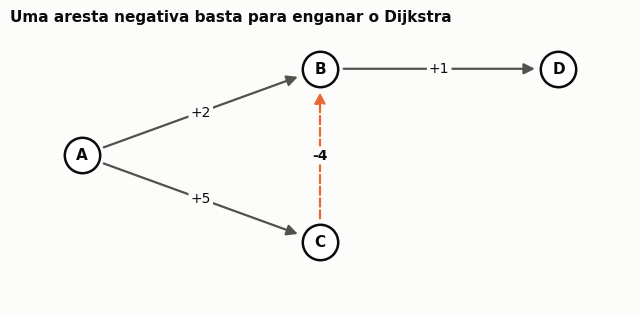

Dijkstra da aula:  A → D custa 3, pelo caminho A → B → D
melhor de verdade: A → C → B → D custa 2


In [17]:
def desenhar_digrafo(pos, arestas, titulo, destaque=(), rotulos=None):
    """Desenha um grafo direcionado com pesos. Aresta negativa = tracejada e laranja.
    destaque: arestas (u, v) a realcar; rotulos: texto extra embaixo de cada vertice."""
    destaque = set(destaque)
    pares = {(u, v) for u, v, _ in arestas}
    fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=FUNDO)
    ax.set_facecolor(FUNDO)
    for u, v, peso in arestas:
        (x1, y1), (x2, y2) = pos[u], pos[v]
        curva = 0.18 if (v, u) in pares else 0.0          # ida e volta: entorta para nao sobrepor
        realce = (u, v) in destaque
        cor = AZUL if realce else (LARANJA if peso < 0 else TINTA_2)
        ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle='-|>', color=cor, lw=3 if realce else 1.6,
                                    linestyle='--' if peso < 0 else '-', shrinkA=17, shrinkB=17,
                                    mutation_scale=16, connectionstyle=f'arc3,rad={curva}'))
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        if curva:                                          # rotulo acompanha a curva
            mx, my = mx + (y2 - y1) * curva / 2, my - (x2 - x1) * curva / 2
        ax.text(mx, my, f"{peso:+g}", ha='center', va='center', fontsize=10, color=TINTA,
                fontweight='bold' if (peso < 0 or realce) else 'normal',
                bbox=dict(boxstyle='round,pad=0.15', fc=FUNDO, ec='none'))
    for vert, (x, y) in pos.items():
        ax.scatter(x, y, s=650, color='white', edgecolor=TINTA, lw=1.8, zorder=3)
        ax.text(x, y, vert, ha='center', va='center', fontsize=11, fontweight='bold', color=TINTA, zorder=4)
        if rotulos:
            ax.text(x, y - 0.33, rotulos[vert], ha='center', va='top', fontsize=9, color=TINTA_2)
    xs, ys = [p[0] for p in pos.values()], [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6); ax.set_ylim(min(ys) - 0.75, max(ys) + 0.45)
    ax.set_title(titulo, loc='left', fontweight='bold', color=TINTA, fontsize=11)
    ax.axis('off')
    plt.show()


# grafo pequeno com UMA aresta negativa (C -> B vale -4)
grafo_neg = {
    'A': {'B': 2, 'C': 5},
    'B': {'D': 1},
    'C': {'B': -4},
    'D': {},
}
desenhar_digrafo({'A': (0, 1), 'B': (2, 2), 'C': (2, 0), 'D': (4, 2)},
                 [(u, v, p) for u in grafo_neg for v, p in grafo_neg[u].items()],
                 'Uma aresta negativa basta para enganar o Dijkstra')

distancia, rota = dijkstra(grafo_neg, 'A', 'D')
print(f"Dijkstra da aula:  A → D custa {distancia}, pelo caminho {' → '.join(rota)}")
print(f"melhor de verdade: A → C → B → D custa {custo(grafo_neg, ['A', 'C', 'B', 'D'])}")


O que aconteceu, passo a passo:

1. `(0, A)` sai: B recebe 2 e C recebe 5.
2. `(2, B)` sai: D recebe 2 + 1 = 3.
3. `(3, D)` sai. **D é o destino, então o código para**, confiando que 3 já é definitivo.
4. `(5, C)` nem chegou a sair do heap. Se saísse, a aresta C → B (−4) daria B = 1 e, passando por B,
   D = 2.

O `break` não é o defeito: ele só aplica a garantia do Dijkstra ("saiu do heap, está pronto"), e é
essa garantia que o peso negativo quebra.

**E sem o `break`?** A implementação da aula não marca vértices como visitados: ela reprocessa um
vértice sempre que ele volta ao heap com distância menor. Sem o `break`, ela até acerta este exemplo:


In [18]:
def dijkstra_sem_break(grafo, origem, limite=1000):
    """O laco da implementacao da aula SEM o 'break' do destino e com um limite de seguranca.
    Conta quantas vezes um vertice sai do heap e e processado."""
    distancias = {vertice: inf for vertice in grafo}
    distancias[origem] = 0
    fila_prioridade = [(0, origem)]
    processados = 0
    while fila_prioridade and processados < limite:
        distancia_atual, u = heapq.heappop(fila_prioridade)
        if distancia_atual > distancias[u]:
            continue
        processados += 1
        for v, peso in grafo[u].items():
            nova_distancia = distancia_atual + peso
            if nova_distancia < distancias[v]:
                distancias[v] = nova_distancia
                heapq.heappush(fila_prioridade, (nova_distancia, v))
    return distancias, processados


distancias, processados = dijkstra_sem_break(grafo_neg, 'A')
print("sem o break:", {v: fmt(d) for v, d in distancias.items()},
      f"| {processados} processamentos para {len(grafo_neg)} vértices")


sem o break: {'A': '0', 'B': '1', 'C': '5', 'D': '2'} | 6 processamentos para 4 vértices


Acertou, mas B e D foram processados **duas vezes** cada: 6 processamentos para 4 vértices. Isso já
não é o Dijkstra. O algoritmo perde a garantia de processar cada vértice uma única vez, e com ela a
complexidade O((V + E) log V): em grafos maiores, os reprocessamentos podem se multiplicar. E, se houver
um ciclo negativo, o laço **nunca termina** (seção 2.5).

**"E se somar uma constante em todos os pesos para eliminar o negativo?"** Também não funciona: um
caminho com *k* arestas ganha *k* vezes a constante, então caminhos com mais arestas são punidos mais
do que os curtos e o menor caminho pode mudar:


In [19]:
# "e se eu somar 4 em todos os pesos para sumir com o negativo?"
deslocado = {u: {v: p + 4 for v, p in viz.items()} for u, viz in grafo_neg.items()}
_, rota = dijkstra(deslocado, 'A', 'D')
print(f"com +4 em tudo, o Dijkstra escolhe {' → '.join(rota)}: custo real {custo(grafo_neg, rota)}")
print(f"o melhor de verdade é A → C → B → D: custo real {custo(grafo_neg, ['A', 'C', 'B', 'D'])}")


com +4 em tudo, o Dijkstra escolhe A → B → D: custo real 3
o melhor de verdade é A → C → B → D: custo real 2


## 2.2 A ideia do Bellman-Ford

A operação básica é a mesma do Dijkstra, o **relaxamento** da aresta u → v:

> se `distancias[u] + peso < distancias[v]`, passar por u é melhor: `distancias[v] = distancias[u] + peso`
> e `predecessores[v] = u`.

A diferença está em **quais** arestas relaxar e **quantas vezes**:

| | Dijkstra | Bellman-Ford |
|---|---|---|
| Quais arestas relaxa | só as que saem do vértice escolhido | **todas**, em qualquer ordem |
| Quantas vezes | cada aresta uma única vez | até **V − 1 rodadas** de todas as arestas |
| Decisão gulosa | sim: o vértice que sai fica definitivo | **não**: nada é definitivo até o fim |
| Pesos negativos | não | **sim** |

Como o Bellman-Ford nunca "fecha" um vértice, uma melhora descoberta tarde (como a de B no exemplo
acima) sempre tem chance de se propagar nas rodadas seguintes.

**Analogia:** pense em uma notícia ("dá para chegar mais barato!") passando de vértice em vértice. Em
cada rodada, ela anda **pelo menos uma aresta** ao longo de cada menor caminho.

### Por que V − 1 rodadas bastam

1. Se não há ciclo negativo, sempre existe um menor caminho **simples**, que não repete vértice: dar
   uma volta num ciclo de custo ≥ 0 nunca deixa o caminho mais barato.
2. Um caminho simples passa por no máximo V vértices, então tem **no máximo V − 1 arestas**.
3. **Invariante:** depois da rodada *k*, a distância guardada para v já é, no máximo, o custo do melhor
   caminho até v que usa **até *k* arestas**. (Por indução: se o melhor caminho com *k* arestas termina em u → v, o
   trecho até u tem *k* − 1 arestas e já estava certo depois da rodada *k* − 1; na rodada *k*, ao
   relaxar u → v, a distância de v recebe esse valor.)
4. Juntando 2 e 3: depois da rodada V − 1, **todas** as distâncias estão certas.

### E se houver ciclo negativo?

Um **ciclo negativo** é um ciclo cuja soma dos pesos é menor que zero. Se a origem alcança um ciclo
assim, o "menor caminho" **não existe**: cada volta no ciclo baixa o custo, até −∞. O Bellman-Ford
detecta isso com uma **rodada extra**: se depois de V − 1 rodadas alguma aresta **ainda** melhora uma
distância, o melhor caminho precisaria de V ou mais arestas, ou seja, repetiria vértice, o que só
compensa se houver um ciclo negativo. Nesse caso o algoritmo **avisa**, em vez de devolver números
errados como o Dijkstra.

### Parada antecipada

Se uma rodada inteira não muda nenhuma distância, a próxima rodada receberia exatamente a mesma entrada
e também não mudaria nada. Então dá para parar antes de V − 1 rodadas, e na prática isso é o comum.

### Pseudocódigo

```
BELLMAN-FORD(vertices, arestas, origem)
1. para cada vertice v:  dist[v] = ∞,  pred[v] = nenhum
   dist[origem] = 0
2. repita V - 1 vezes:
       para cada aresta (u, v, peso):
           se dist[u] + peso < dist[v]:
               dist[v] = dist[u] + peso
               pred[v] = u
       se nada mudou nesta rodada: pare
3. para cada aresta (u, v, peso):
       se dist[u] + peso < dist[v]:  existe ciclo negativo
4. devolva dist e pred
```


## 2.3 Implementação

Como o algoritmo passa por **todas as arestas** a cada rodada, a representação mais natural é uma
**lista de arestas** `(u, v, peso)`. A função `arestas_de` converte o dicionário de dicionários usado no
Dijkstra para esse formato.


In [20]:
def arestas_de(grafo):
    """Converte o dicionario de dicionarios em lista de arestas (u, v, peso)."""
    return [(u, v, peso) for u in grafo for v, peso in grafo[u].items()]


def remontar_caminho(predecessores, destino):
    """Volta pelos predecessores, do destino ate a origem (a etapa 4 do Dijkstra da aula)."""
    caminho = []
    while destino is not None:
        caminho.append(destino)
        destino = predecessores[destino]
    return caminho[::-1]


def extrair_ciclo(predecessores, v, n):
    """Volta n passos pelos predecessores (assim cai com certeza dentro do ciclo) e recolhe o ciclo."""
    for _ in range(n):
        v = predecessores[v]
    ciclo = [v]
    u = predecessores[v]
    while u != v:
        ciclo.append(u)
        u = predecessores[u]
    ciclo.append(v)
    return ciclo[::-1]                           # na ordem em que as arestas sao percorridas


def bellman_ford(vertices, arestas, origem, mostrar=False):
    """Menor custo da origem ate cada vertice, aceitando pesos negativos.
    Devolve (distancias, predecessores, ciclo, rodadas); ciclo = None quando nao ha ciclo negativo."""
    # 1) inicializacao: igual a do Dijkstra
    distancias = {v: inf for v in vertices}
    predecessores = {v: None for v in vertices}
    distancias[origem] = 0

    # 2) ate V - 1 rodadas; em cada uma, tenta relaxar TODAS as arestas
    rodadas, mudou = 0, False
    for rodada in range(1, len(vertices)):
        rodadas, mudou = rodada, False
        if mostrar:
            print(f"Rodada {rodada}")
        for u, v, peso in arestas:
            rotulo = f"{u}→{v} ({peso:+g})"
            if distancias[u] == inf:             # u ainda nao foi alcancado: nao tem o que propagar
                if mostrar:
                    print(f"  {rotulo:<11} {u} = ∞, ainda não alcançado: pula")
                continue
            nova_distancia = distancias[u] + peso
            conta = f"{fmt(distancias[u])} {'+' if peso >= 0 else '-'} {fmt(abs(peso))} = {fmt(nova_distancia)}"
            if nova_distancia < distancias[v]:   # relaxamento: passar por u ficou mais barato
                if mostrar:
                    print(f"  {rotulo:<11} {conta} < {fmt(distancias[v])}  → {v} = {fmt(nova_distancia)}")
                distancias[v] = nova_distancia
                predecessores[v] = u
                mudou = True
            elif mostrar:
                print(f"  {rotulo:<11} {conta}, não melhora {v} = {fmt(distancias[v])}")
        if mostrar:
            print("  distâncias:", "  ".join(f"{x}={fmt(distancias[x])}" for x in vertices))
        if not mudou:                            # rodada inteira sem mudanca: ja convergiu
            if mostrar:
                print("  nenhuma mudança nesta rodada: pode parar antes do limite")
            break
    if mostrar and mudou:
        print(f"limite de V - 1 = {len(vertices) - 1} rodadas atingido")

    # 3) checagem: se alguma aresta AINDA melhora, existe ciclo negativo
    for u, v, peso in arestas:
        if distancias[u] != inf and distancias[u] + peso < distancias[v]:
            if mostrar:
                print(f"Checagem: {u}→{v} ainda melhora: existe ciclo negativo")
            predecessores[v] = u
            return distancias, predecessores, extrair_ciclo(predecessores, v, len(vertices)), rodadas
    if mostrar:
        print("Checagem: nenhuma aresta melhora mais, então não há ciclo negativo")
    return distancias, predecessores, None, rodadas


Pontos do código:

- **`if distancias[u] == inf`**: um vértice que ainda não foi alcançado não tem distância para
  propagar. (Em Python `inf - 4` continua `inf` e o teste daria certo de qualquer jeito, mas o `if`
  deixa a intenção clara e é o que permite o `print` explicativo.)
- **`mudou`**: liga a parada antecipada.
- **Checagem final**: se uma aresta ainda relaxa, a função devolve o ciclo. `extrair_ciclo` volta V
  passos pelos predecessores a partir do vértice que melhorou: depois de V passos já se está, com
  certeza, dentro do ciclo, e aí basta seguir os predecessores até voltar ao mesmo vértice.
- **`remontar_caminho`** é a etapa 4 do Dijkstra da aula separada em uma função: como o Bellman-Ford
  calcula a distância de **todos** os vértices de uma vez, o caminho é remontado para o destino que se
  quiser.
- **`mostrar=True`** imprime cada aresta testada em cada rodada; é o que vamos usar no passo a passo.

Os nomes `distancias` e `predecessores` são os mesmos do código da aula. Primeiro, o grafo que enganou
o Dijkstra na seção 2.1:


In [21]:
distancias, predecessores, ciclo, rodadas = bellman_ford(list(grafo_neg), arestas_de(grafo_neg), 'A')
print("Bellman-Ford:", {v: fmt(d) for v, d in distancias.items()}, f"| ciclo negativo: {ciclo} | rodadas: {rodadas}")
print(f"caminho até D: {' → '.join(remontar_caminho(predecessores, 'D'))} = {distancias['D']}")


Bellman-Ford: {'A': '0', 'B': '1', 'C': '5', 'D': '2'} | ciclo negativo: None | rodadas: 3
caminho até D: A → C → B → D = 2


Agora D sai com **2**, pelo caminho certo A → C → B → D. Foram 3 rodadas (o limite V − 1 = 3):
na rodada 1 a aresta negativa baixou B para 1, na rodada 2 essa melhora chegou a D, e a rodada 3 não
mudou mais nada. É exatamente a propagação que faltou ao Dijkstra.


## 2.4 Exemplo passo a passo

Grafo direcionado com 5 vértices e 8 arestas, duas delas negativas (B → C = −2 e D → E = −4). Origem: **A**.

As arestas estão listadas **"de trás para frente"** de propósito (as que saem de A por último). Para
este grafo é o pior caso, e é o que melhor mostra a melhora andando uma aresta por rodada. Repare
também que existe um ciclo, C → D → E → C, mas ele custa 3 − 4 + 2 = **+1**, então **não** é negativo
e não atrapalha.


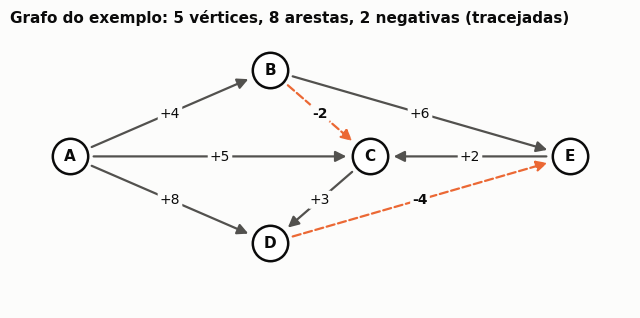

In [22]:
vertices = ['A', 'B', 'C', 'D', 'E']
# ordem "de tras para frente" de proposito: e o pior caso para este grafo
arestas = [
    ('D', 'E', -4),
    ('C', 'D', 3),
    ('E', 'C', 2),
    ('B', 'C', -2),
    ('B', 'E', 6),
    ('A', 'B', 4),
    ('A', 'C', 5),
    ('A', 'D', 8),
]
POS_EX = {'A': (0, 1), 'B': (2, 2), 'C': (3, 1), 'D': (2, 0), 'E': (5, 1)}
desenhar_digrafo(POS_EX, arestas, 'Grafo do exemplo: 5 vértices, 8 arestas, 2 negativas (tracejadas)')


In [23]:
distancias, predecessores, ciclo, rodadas = bellman_ford(vertices, arestas, 'A', mostrar=True)


Rodada 1
  D→E (-4)    D = ∞, ainda não alcançado: pula
  C→D (+3)    C = ∞, ainda não alcançado: pula
  E→C (+2)    E = ∞, ainda não alcançado: pula
  B→C (-2)    B = ∞, ainda não alcançado: pula
  B→E (+6)    B = ∞, ainda não alcançado: pula
  A→B (+4)    0 + 4 = 4 < ∞  → B = 4
  A→C (+5)    0 + 5 = 5 < ∞  → C = 5
  A→D (+8)    0 + 8 = 8 < ∞  → D = 8
  distâncias: A=0  B=4  C=5  D=8  E=∞
Rodada 2
  D→E (-4)    8 - 4 = 4 < ∞  → E = 4
  C→D (+3)    5 + 3 = 8, não melhora D = 8
  E→C (+2)    4 + 2 = 6, não melhora C = 5
  B→C (-2)    4 - 2 = 2 < 5  → C = 2
  B→E (+6)    4 + 6 = 10, não melhora E = 4
  A→B (+4)    0 + 4 = 4, não melhora B = 4
  A→C (+5)    0 + 5 = 5, não melhora C = 2
  A→D (+8)    0 + 8 = 8, não melhora D = 8
  distâncias: A=0  B=4  C=2  D=8  E=4
Rodada 3
  D→E (-4)    8 - 4 = 4, não melhora E = 4
  C→D (+3)    2 + 3 = 5 < 8  → D = 5
  E→C (+2)    4 + 2 = 6, não melhora C = 2
  B→C (-2)    4 - 2 = 2, não melhora C = 2
  B→E (+6)    4 + 6 = 10, não melhora E = 4
  A→B (+

### Lendo a execução

**Rodada 1.** Só A tem distância conhecida. As cinco primeiras arestas saem de vértices que ainda estão
em ∞ e são puladas. Mesmo B → C e B → E são pulados, porque, quando foram testados, A → B ainda não
tinha sido relaxada **nesta rodada**. No fim da rodada, as arestas de A dão B = 4, C = 5 e D = 8.

**Rodada 2.** Com B, C e D conhecidos, duas melhoras: D → E dá E = 8 − 4 = **4**, e o atalho negativo
B → C dá C = 4 − 2 = **2**, melhor que os 5 da aresta direta A → C.

**Rodada 3.** C melhorou na rodada anterior, então agora C → D dá D = 2 + 3 = **5**, melhor que os 8 da
aresta direta.

**Rodada 4.** D melhorou, então D → E dá E = 5 − 4 = **1**. O limite de V − 1 = 4 rodadas foi atingido.

**Checagem.** Nenhuma aresta melhora mais nada, então não há ciclo negativo e as distâncias são finais.

| Depois da rodada | A | B | C | D | E | O que mudou |
|---|---|---|---|---|---|---|
| início | 0 | ∞ | ∞ | ∞ | ∞ | só a origem é conhecida |
| 1 | 0 | 4 | 5 | 8 | ∞ | as arestas que saem de A |
| 2 | 0 | 4 | **2** | 8 | **4** | atalho negativo B → C; E alcançado por D |
| 3 | 0 | 4 | 2 | **5** | 4 | D melhora porque C melhorou |
| 4 | 0 | 4 | 2 | 5 | **1** | E melhora porque D melhorou |

Observe a **cascata** na diagonal: C melhora na rodada 2, D na 3, E na 4. É o invariante da seção 2.2
na prática: o melhor caminho até E é A → B → C → D → E, com **4 arestas**, e por isso precisou de 4
rodadas. Cada rodada empurrou a informação uma aresta para frente.


vértice  custo   caminho
A            0   A
B            4   A → B
C            2   A → B → C
D            5   A → B → C → D
E            1   A → B → C → D → E

rodadas usadas: 4 (limite V - 1 = 4) | ciclo negativo: None


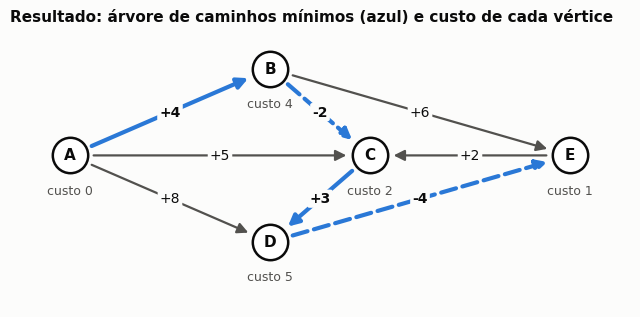

In [24]:
print(f"{'vértice':<8} {'custo':>5}   caminho")
for v in vertices:
    print(f"{v:<8} {fmt(distancias[v]):>5}   {' → '.join(remontar_caminho(predecessores, v))}")
print(f"\nrodadas usadas: {rodadas} (limite V - 1 = {len(vertices) - 1}) | ciclo negativo: {ciclo}")

arvore = [(predecessores[v], v) for v in vertices if predecessores[v] is not None]   # quem veio de quem
desenhar_digrafo(POS_EX, arestas, 'Resultado: árvore de caminhos mínimos (azul) e custo de cada vértice',
                 destaque=arvore, rotulos={v: f"custo {fmt(distancias[v])}" for v in vertices})


### A ordem das arestas muda a velocidade, não o resultado

Com as mesmas arestas em ordem "boa" (primeiro as que saem de A, depois as de B, de C...), cada
melhora já é aproveitada pelas arestas seguintes **na mesma rodada**:


In [25]:
# mesmas arestas, agora na ordem "boa": primeiro as que saem de A, depois de B, C...
arestas_boas = sorted(arestas, key=lambda a: vertices.index(a[0]))
dist2, _, _, rodadas2 = bellman_ford(vertices, arestas_boas, 'A', mostrar=True)
print(f"\nmesmo resultado: {dist2 == distancias} | rodadas: {rodadas2} em vez de {rodadas}")


Rodada 1
  A→B (+4)    0 + 4 = 4 < ∞  → B = 4
  A→C (+5)    0 + 5 = 5 < ∞  → C = 5
  A→D (+8)    0 + 8 = 8 < ∞  → D = 8
  B→C (-2)    4 - 2 = 2 < 5  → C = 2
  B→E (+6)    4 + 6 = 10 < ∞  → E = 10
  C→D (+3)    2 + 3 = 5 < 8  → D = 5
  D→E (-4)    5 - 4 = 1 < 10  → E = 1
  E→C (+2)    1 + 2 = 3, não melhora C = 2
  distâncias: A=0  B=4  C=2  D=5  E=1
Rodada 2
  A→B (+4)    0 + 4 = 4, não melhora B = 4
  A→C (+5)    0 + 5 = 5, não melhora C = 2
  A→D (+8)    0 + 8 = 8, não melhora D = 5
  B→C (-2)    4 - 2 = 2, não melhora C = 2
  B→E (+6)    4 + 6 = 10, não melhora E = 1
  C→D (+3)    2 + 3 = 5, não melhora D = 5
  D→E (-4)    5 - 4 = 1, não melhora E = 1
  E→C (+2)    1 + 2 = 3, não melhora C = 2
  distâncias: A=0  B=4  C=2  D=5  E=1
  nenhuma mudança nesta rodada: pode parar antes do limite
Checagem: nenhuma aresta melhora mais, então não há ciclo negativo

mesmo resultado: True | rodadas: 2 em vez de 4


Na rodada 1 a melhora atravessou o caminho inteiro A → B → C → D → E de uma vez; a rodada 2 só
confirmou que nada mais muda e acionou a parada antecipada. O resultado é o mesmo; a quantidade de
trabalho, não. Por isso a complexidade é dada pelo **pior caso**, V − 1 rodadas.


## 2.5 Detectando ciclo negativo

Agora um grafo em que B → C → D → B soma 3 + 2 − 6 = **−1**. Cada volta nesse ciclo deixa os caminhos
até B, C, D e E um pouco mais baratos, sem limite.


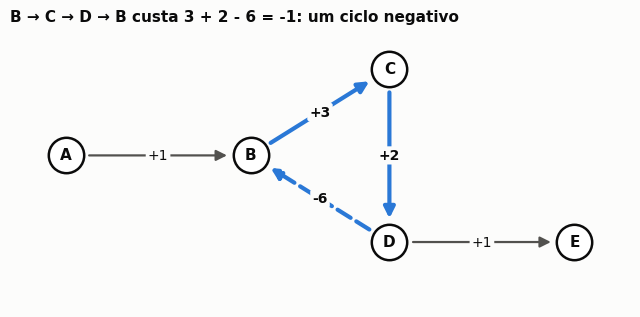

Bellman-Ford encontrou o ciclo negativo: D → B → C → D
custo de uma volta: -1
distâncias depois de V - 1 rodadas (sem significado, mudariam a cada volta): {'A': '0', 'B': '-3', 'C': '1', 'D': '3', 'E': '4'}

Dijkstra da aula sem o break: parou no limite de segurança, depois de 1000 processamentos
distâncias nesse momento: {'A': '0', 'B': '-332', 'C': '-328', 'D': '-326', 'E': '-325'}


In [26]:
vertices_c = ['A', 'B', 'C', 'D', 'E']
arestas_c = [('A', 'B', 1), ('B', 'C', 3), ('C', 'D', 2), ('D', 'B', -6), ('D', 'E', 1)]
desenhar_digrafo({'A': (0, 1), 'B': (2, 1), 'C': (3.5, 2), 'D': (3.5, 0), 'E': (5.5, 0)}, arestas_c,
                 'B → C → D → B custa 3 + 2 - 6 = -1: um ciclo negativo',
                 destaque=[('B', 'C'), ('C', 'D'), ('D', 'B')])

dist_c, pred_c, ciclo, rodadas = bellman_ford(vertices_c, arestas_c, 'A')
peso = {(u, v): p for u, v, p in arestas_c}
print("Bellman-Ford encontrou o ciclo negativo:", ' → '.join(ciclo))
print("custo de uma volta:", sum(peso[a] for a in zip(ciclo, ciclo[1:])))
print("distâncias depois de V - 1 rodadas (sem significado, mudariam a cada volta):",
      {v: fmt(d) for v, d in dist_c.items()})

# e o laco do Dijkstra da aula, sem o break, neste grafo?
grafo_c = {v: {} for v in vertices_c}
for u, v, p in arestas_c:
    grafo_c[u][v] = p
dist_sb, processados = dijkstra_sem_break(grafo_c, 'A', limite=1000)
print(f"\nDijkstra da aula sem o break: parou no limite de segurança, depois de {processados} processamentos")
print("distâncias nesse momento:", {v: fmt(d) for v, d in dist_sb.items()})


Depois das V − 1 rodadas a aresta D → B ainda melhorava B, e o Bellman-Ford devolveu o ciclo
D → B → C → D (o mesmo da figura, começando em outro vértice), de custo −1. As distâncias impressas
não valem nada: mais uma rodada e todas baixariam de novo. Por isso, havendo ciclo negativo, a
resposta certa é **"não existe menor caminho"**, e o Bellman-Ford consegue dizer isso.

O laço do Dijkstra da aula sem o `break` só parou porque bateu no limite de segurança: cada volta no
ciclo baixa B, C e D em 1 e coloca tudo de novo no heap, sem fim. Com o `break` e E como destino também
não termina: as tuplas do ciclo são sempre menores que as de E, então E nunca chega ao topo do heap.


## 2.6 Aplicação: arbitragem de câmbio

Detectar ciclo negativo tem uso prático. Uma **arbitragem** é uma sequência de trocas de moeda que
termina na moeda inicial com **mais** dinheiro do que começou. Se `taxa(a → b)` é quanto de *b* se
recebe por 1 unidade de *a*, um ciclo a → b → c → a dá lucro quando

  taxa(a→b) · taxa(b→c) · taxa(c→a) > 1.

O Bellman-Ford **soma** pesos, não multiplica. O logaritmo transforma produto em soma, e o sinal de
menos transforma "maior que 1" em "menor que 0":

  produto > 1 ⟺ soma dos log(taxa) > 0 ⟺ **soma dos −log(taxa) < 0**.

Ou seja: com peso **−log(taxa)** em cada aresta, **arbitragem = ciclo negativo**. As taxas abaixo são
**fictícias**: em cada troca o banco cobra 1% de *spread*, menos em três taxas cruzadas que estão
levemente fora do lugar.


In [27]:
import math

moedas = ['BRL', 'USD', 'EUR', 'GBP']
# taxa[(a, b)] = quanto de b se recebe por 1 unidade de a   (valores FICTICIOS)
taxa = {
    ('BRL', 'USD'): 0.1833, ('BRL', 'EUR'): 0.1692, ('BRL', 'GBP'): 0.1435,
    ('USD', 'BRL'): 5.346,  ('USD', 'EUR'): 0.9268, ('USD', 'GBP'): 0.7748,
    ('EUR', 'BRL'): 5.7915, ('EUR', 'USD'): 1.0725, ('EUR', 'GBP'): 0.8512,
    ('GBP', 'BRL'): 6.831,  ('GBP', 'USD'): 1.2829, ('GBP', 'EUR'): 1.1677,
}
print("de \\ para" + "".join(f"{m:>9}" for m in moedas))
for a in moedas:
    print(f"{a:<9}" + "".join(f"{'-':>9}" if a == b else f"{taxa[(a, b)]:>9.4f}" for b in moedas))

# produto de taxas > 1  <=>  soma de -log(taxa) < 0  <=>  ciclo negativo
arestas_cambio = [(a, b, -math.log(t)) for (a, b), t in taxa.items()]
_, _, ciclo, _ = bellman_ford(moedas, arestas_cambio, 'BRL')

fator = math.prod(taxa[par] for par in zip(ciclo, ciclo[1:]))
print("\nciclo de arbitragem:", ' → '.join(ciclo))
print(f"produto das taxas: {fator:.5f}  (ganho de {(fator - 1) * 100:.2f}% por volta)")
valor = 1000.0
for a, b in zip(ciclo, ciclo[1:]):
    novo = valor * taxa[(a, b)]
    print(f"  {valor:>9.2f} {a} → {novo:>9.2f} {b}")
    valor = novo


de \ para      BRL      USD      EUR      GBP
BRL              -   0.1833   0.1692   0.1435
USD         5.3460        -   0.9268   0.7748
EUR         5.7915   1.0725        -   0.8512
GBP         6.8310   1.2829   1.1677        -

ciclo de arbitragem: USD → EUR → GBP → USD
produto das taxas: 1.01207  (ganho de 1.21% por volta)
    1000.00 USD →    926.80 EUR
     926.80 EUR →    788.89 GBP
     788.89 GBP →   1012.07 USD


O Bellman-Ford achou o ciclo USD → EUR → GBP → USD: três taxas que, isoladas, parecem normais, mas
cujo produto é maior que 1. Nenhuma troca de ida e volta (por exemplo USD → EUR → USD) dá lucro; só o
triângulo dá. Em mercados reais essas distorções duram frações de segundo e as tarifas costumam
consumir o ganho, mas é exatamente essa a técnica usada por sistemas que procuram arbitragem: montar
o grafo de moedas com −log(taxa) e procurar ciclos negativos.


## 2.7 Complexidade do Bellman-Ford

| Etapa | Quantas vezes | Custo de cada | Total |
|---|---|---|---|
| inicializar `distancias` e `predecessores` | 1 | O(V) | O(V) |
| relaxar todas as arestas | V − 1 rodadas × E arestas | O(1) | **O(V·E)** |
| rodada de checagem do ciclo negativo | E arestas | O(1) | O(E) |
| **total (tempo)** | | | **O(V·E)** |
| **memória** | | | **O(V)** para `distancias` e `predecessores` (além da própria lista de arestas) |

- **Melhor caso**, com parada antecipada: uma rodada útil e uma de confirmação, **O(E)**.
- **Grafo denso** (E ≈ V²): **O(V³)**. **Grafo esparso** (E ≈ V): O(V²).

**Comparação com os algoritmos vistos no curso:**

| Algoritmo | Pesos aceitos | Tempo | Detecta ciclo negativo? |
|---|---|---|---|
| BFS (Atividade 06) | sem peso (todas as arestas valem 1) | O(V + E) | não se aplica |
| Dijkstra sem heap | ≥ 0 | O(V²) | não |
| Dijkstra com Min-Heap | ≥ 0 | O((V + E) log V) | não |
| **Bellman-Ford** | **qualquer, inclusive negativos** | **O(V·E)** | **sim** |

O Bellman-Ford é mais lento, e esse é o preço de aceitar pesos negativos: sem uma escolha gulosa, ele
não sabe qual vértice já está pronto e precisa repetir o trabalho.

### Conferência automática e o pior caso medido

A célula abaixo faz três testes:

- **(a)** em um grafo aleatório com pesos ≥ 0, o Bellman-Ford precisa dar o mesmo que o Dijkstra
  (conferido em 100 destinos sorteados, porque o Dijkstra da aula responde um destino por vez);
- **(b)** no mesmo grafo, cria pesos negativos **sem** criar ciclo negativo, somando a cada aresta
  `h(u) − h(v)` para valores aleatórios `h`. Em qualquer caminho de s até v, os `h` do meio se
  cancelam e sobra `h(s) − h(v)`, então a resposta certa é conhecida: `dist_original(v) + h(s) − h(v)`.
  (É o truque do **algoritmo de Johnson**, que usa o Bellman-Ford para tirar os negativos e depois roda
  o Dijkstra.)
- **(c)** o pior caso de propósito: um caminho em linha com as arestas na ordem inversa, que obriga
  as V − 1 rodadas.


In [28]:
def com_potencial(grafo, semente=7):
    """Cria pesos negativos SEM ciclo negativo: w'(u,v) = w(u,v) + h(u) - h(v).
    Num ciclo os h se cancelam, entao o custo de qualquer ciclo continua >= 0."""
    rng = random.Random(semente)
    h = {v: rng.randint(-60, 60) for v in grafo}
    return {u: {v: p + h[u] - h[v] for v, p in viz.items()} for u, viz in grafo.items()}, h


g = grafo_aleatorio(2000, 5)
n_arestas = sum(len(viz) for viz in g.values())
destinos = random.Random(1).sample(list(g), 100)            # o Dijkstra da aula responde um destino por vez
dist_dij = {v: dijkstra(g, 0, v)[0] for v in destinos}

# (a) pesos >= 0: Bellman-Ford tem que concordar com o Dijkstra
inicio = time.perf_counter()
dist_bf, _, ciclo, rodadas = bellman_ford(list(g), arestas_de(g), 0)
t_bf = (time.perf_counter() - inicio) * 1000
assert ciclo is None and all(dist_bf[v] == dist_dij[v] for v in destinos)
t_dij = cronometrar(dijkstra, {**g, len(g): {}}, 0, len(g))   # destino isolado: Dijkstra completo
print(f"(a) V = {milhar(len(g))}, E = {milhar(n_arestas)}, pesos >= 0: igual ao Dijkstra nos 100 destinos; "
      f"{rodadas} rodadas de no máximo {len(g) - 1}; {t_bf:.0f} ms (Dijkstra: {t_dij:.1f} ms)")

# (b) com pesos negativos (mas sem ciclo negativo): a resposta certa sai do Dijkstra no grafo original
g_neg, h = com_potencial(g)
negativas = sum(p < 0 for viz in g_neg.values() for p in viz.values())
dist_bf, _, ciclo, rodadas = bellman_ford(list(g_neg), arestas_de(g_neg), 0)
assert ciclo is None and all(dist_bf[v] == dist_dij[v] + h[0] - h[v] for v in destinos)
print(f"(b) mesmo grafo com {milhar(negativas)} arestas negativas: Bellman-Ford correto, {rodadas} rodadas")

# (c) pior caso: um caminho em linha com as arestas na ordem inversa precisa de V - 1 rodadas
for n in (300, 600, 1200):
    linha = [(i, i + 1, 1) for i in reversed(range(n - 1))]
    t = inf
    for _ in range(3):                           # melhor de 3, como no cronometrar
        inicio = time.perf_counter()
        _, _, _, rodadas = bellman_ford(list(range(n)), linha, 0)
        t = min(t, (time.perf_counter() - inicio) * 1000)
    print(f"(c) linha com V = {milhar(n):>5}: {rodadas:>4} rodadas × {len(linha):>4} arestas "
          f"= {milhar(rodadas * len(linha)):>9} relaxamentos, {t:>6.0f} ms")


(a) V = 2 000, E = 11 994, pesos >= 0: igual ao Dijkstra nos 100 destinos; 8 rodadas de no máximo 1999; 128 ms (Dijkstra: 2.4 ms)
(b) mesmo grafo com 2 302 arestas negativas: Bellman-Ford correto, 8 rodadas


(c) linha com V =   300:  299 rodadas ×  299 arestas =    89 401 relaxamentos,     69 ms


(c) linha com V =   600:  599 rodadas ×  599 arestas =   358 801 relaxamentos,    283 ms


(c) linha com V = 1 200: 1199 rodadas × 1199 arestas = 1 437 601 relaxamentos,   1242 ms


Os três testes passaram (nenhum `assert` falhou):

- **(a)** Com 2 000 vértices e cerca de 12 000 arestas, o Bellman-Ford deu as mesmas distâncias do
  Dijkstra nos 100 destinos conferidos e convergiu em **8 rodadas**, longe do limite de 1 999, graças à parada antecipada. Mesmo
  assim levou bem mais tempo que o Dijkstra no mesmo grafo, porque cada rodada passa por todas as arestas.
- **(b)** Com cerca de 2 300 arestas negativas, a resposta bateu com a calculada pelo Dijkstra no grafo
  original.
- **(c)** No pior caso todas as rodadas são necessárias: (V − 1) rodadas × (V − 1) arestas. Cada vez que
  V dobra, o número de relaxamentos e o tempo ficam cerca de **4 vezes maiores**, que é o O(V·E) previsto
  (aqui E ≈ V, então V·E ≈ V²).

## Resumo

- **Min-Heap** é uma árvore binária completa guardada em uma lista, com o menor item sempre na raiz.
  Inserir e retirar o mínimo custam O(log n). O `heapq` do Python implementa isso sobre uma `list`.
- No **Dijkstra**, o passo mais repetido é escolher o vértice de menor distância. Varrendo a lista, o
  algoritmo custa **O(V²)**; com o Min-Heap, **O((V + E) log V)**, muito mais rápido nos grafos
  esparsos do mundo real. Em grafos densos a vantagem some, e a versão sem heap pode até ganhar.
- O Dijkstra **não funciona com pesos negativos**, porque fecha cada vértice cedo demais.
- O **Bellman-Ford** relaxa todas as arestas por até V − 1 rodadas, aceita pesos negativos, **detecta
  ciclos negativos** e custa **O(V·E)**.

## Referências

- Implementação disponibilizada na aula: `dijkstra_heap.py` (Dijkstra com `heapq`, comentado pela IA
  Gemini 2.5 Pro), usada sem alterações na questão 1.
- BHARGAVA, A. Y. *Entendendo Algoritmos*. São Paulo: Novatec, 2017. Cap. 7 (Algoritmo de Dijkstra e
  a restrição a pesos negativos).
- CORMEN, T. H. et al. *Algoritmos: teoria e prática*. 3. ed. Rio de Janeiro: Elsevier, 2012. Cap. 6
  (heaps) e cap. 24 (caminhos mínimos de fonte única: Bellman-Ford e Dijkstra).
- Documentação do Python: [`heapq`](https://docs.python.org/3/library/heapq.html).
- CP-Algorithms: [Bellman-Ford](https://cp-algorithms.com/graph/bellman_ford.html) (recuperação do ciclo negativo).
- Comparação e implementações feitas com apoio de IA, como o enunciado permite; os resultados foram
  conferidos pelos testes (`assert`) do próprio notebook.
